## Anaylsis of Chess games - Logistic Regression

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)
# For this example, we dont care about draws, so we will filter them out
data = data[data['winner'] != 'draw']
data.head(1)


,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
id,,,,,,,,,,,,,,,
TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5


In [4]:
# Calculate the Elo rating difference between white and black players
data['elo_diff'] = data['white_rating'] - data['black_rating']


In [5]:
# Extract the Elo rating difference and winner columns for analysis
X = data[['elo_diff']]
y = data['winner']

# Replace 'white' with 1 and 'black' with 0 for logistic regression
y = np.where(y == 'white', 1, 0)


In [6]:
# Split the data into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [7]:
# 4. Feature Scaling (Crucial for Logistic Regression optimization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# 5. Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [9]:
# 6. Predict class labels and probabilities on the test set
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)  # Outputs probabilities for each class


/home/oliwier/Projects/DataSciencePortfolio/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


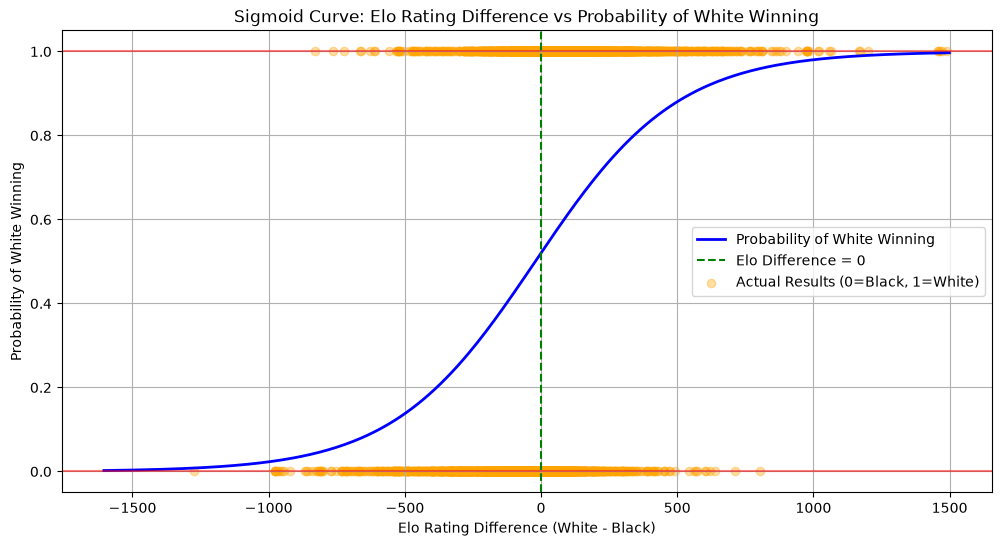

In [10]:
# 7. Plot the sigmoid curve to visualize the relationship between Elo rating difference and the probability of white winning
# Evaluate the fitted model on an ordered grid of Elo differences.
x_curve = np.linspace(X['elo_diff'].min(), X['elo_diff'].max(), 300)
x_curve_scaled = scaler.transform(x_curve.reshape(-1, 1))
y_curve = model.predict_proba(x_curve_scaled)[:, 1]


plt.figure(figsize=(12, 6))
plt.plot(x_curve, y_curve, color='blue', label='Probability of White Winning', linewidth=2)
plt.title('Sigmoid Curve: Elo Rating Difference vs Probability of White Winning')
plt.ylabel('Probability of White Winning')

# Add visual anchors 
plt.axhline(1, color='red', alpha=0.5)
plt.axhline(0, color='red', alpha=0.5)
plt.axvline(0, color='green', linestyle='--', label='Elo Difference = 0')
plt.xlabel('Elo Rating Difference (White - Black)')

# Scatter the actual results for reference
plt.scatter(X_test['elo_diff'], y_test, color='orange', alpha=0.35, label='Actual Results (0=Black, 1=White)')
plt.legend()
plt.grid()
plt.show()

Accuracy Score: 0.65

Confusion Matrix:
 [[1055  777]
 [ 566 1424]]

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.58      0.61      1832
           1       0.65      0.72      0.68      1990

    accuracy                           0.65      3822
   macro avg       0.65      0.65      0.65      3822
weighted avg       0.65      0.65      0.65      3822



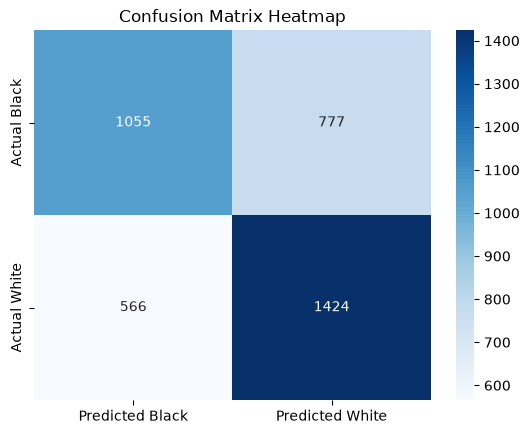

In [15]:
# Display confusion matrix as a heatmap for better visualization
import seaborn as sn

# Print the model accuracy
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
xLabels = ['Predicted Black', 'Predicted White']
yLabels = ['Actual Black', 'Actual White']
sn.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=xLabels, yticklabels=yLabels)
plt.title('Confusion Matrix Heatmap')
plt.show()

Since the confusion matrix accuracy is at 65%, there is clearly more to a game than just rating difference. Lets see what happens if we specify only rated games.

/home/oliwier/Projects/DataSciencePortfolio/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


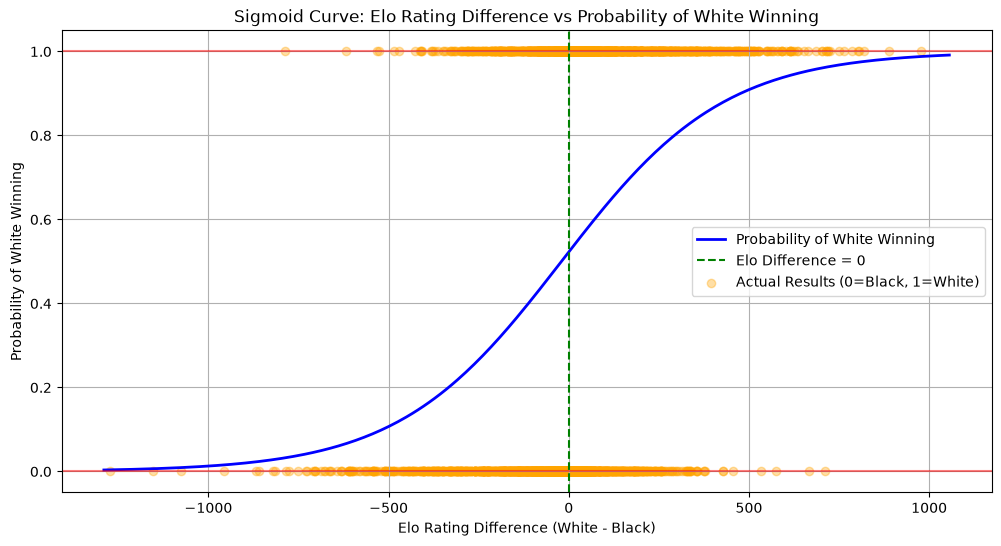

In [18]:
# Remove the 'elo_diff' column 

data = data[data['rated'] != False]  # Filter out unrated games
data['elo_diff'] = data['white_rating'] - data['black_rating']
X = data[['elo_diff']]
y = data['winner']

# Replace 'white' with 1 and 'black' with 0 for logistic regression
y = np.where(y == 'white', 1, 0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled) 

x_curve = np.linspace(X['elo_diff'].min(), X['elo_diff'].max(), 300)
x_curve_scaled = scaler.transform(x_curve.reshape(-1, 1))
y_curve = model.predict_proba(x_curve_scaled)[:, 1]


plt.figure(figsize=(12, 6))
plt.plot(x_curve, y_curve, color='blue', label='Probability of White Winning', linewidth=2)
plt.title('Sigmoid Curve: Elo Rating Difference vs Probability of White Winning')
plt.ylabel('Probability of White Winning')

# Add visual anchors 
plt.axhline(1, color='red', alpha=0.5)
plt.axhline(0, color='red', alpha=0.5)
plt.axvline(0, color='green', linestyle='--', label='Elo Difference = 0')
plt.xlabel('Elo Rating Difference (White - Black)')

# Scatter the actual results for reference
plt.scatter(X_test['elo_diff'], y_test, color='orange', alpha=0.35, label='Actual Results (0=Black, 1=White)')
plt.legend()
plt.grid()
plt.show()

Alright, the graph looks a bit similar, lets analyse the new confusion matrix

Accuracy Score: 0.63

Confusion Matrix:
 [[ 833  672]
 [ 474 1109]]

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.55      0.59      1505
           1       0.62      0.70      0.66      1583

    accuracy                           0.63      3088
   macro avg       0.63      0.63      0.63      3088
weighted avg       0.63      0.63      0.63      3088



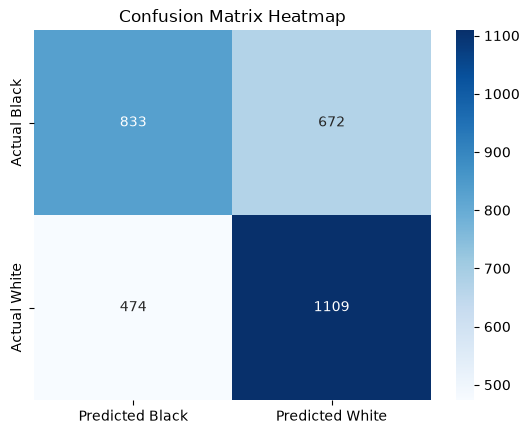

In [19]:
# Print the new model accuracy
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
xLabels = ['Predicted Black', 'Predicted White']
yLabels = ['Actual Black', 'Actual White']
sn.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=xLabels, yticklabels=yLabels)
plt.title('Confusion Matrix Heatmap')
plt.show()

Interesting, the confusion matrix becomes slightly worse when only factoring in only rated games. These results indicate that a simply one-feature model baseline is not enough to predict a comprehensive chess outcome
